# Eine lokale Leere?

PLATZHALTER

#### **Hintergrund**

PLATZHALTER

#### **Theorie**

PLATZHALTER

#### **Daten**

- **Pantheon+ und SH0ES** (Scolnic et al. 2022, Brout et al. 2022, Riess et al. 2022): dieselben 1701 Lichtkurven von Supernovae vom Typ Ia mit Kovarianzmatrix wie in [Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb), aus dem GitHub-Repository `PantheonPlusSH0ES/DataRelease`. Wichtig sind hier die beiden Rotverschiebungen `zCMB` (ohne Korrektur der Eigenbewegungen) und `zHD` (mit Korrektur) und die Kalibratoren mit Cepheiden-Entfernung.
- **Die KBC-Leere:** Keenan, Barger & Cowie (2013) fanden in Zählungen von Galaxien im nahen Infrarot eine Unterdichte von 46 ± 6 % zwischen etwa 40 und 300 Mpc um die Milchstraße (in der Form, wie Haslbauer et al. 2020 sie angeben). Diese Zahlen sind im Code als Konstanten eingetragen.
- **Kosmologische Parameter von Planck 2018** für das Leistungsspektrum der Dichteschwankungen: h = 0.674, Ω_m = 0.315, Ω_b = 0.0493, n_s = 0.965, σ₈ = 0.811.

**Hintergrund & Fachbegriffe:**
- **Dichtekontrast:** δ = ρ/ρ̄ − 1; eine Leere hat δ < 0, δ = −0.46 heißt 46 % weniger Materie als im Mittel des Universums.
- **KBC:** nach Keenan, Barger und Cowie; die Leere wird auch „lokales Loch“ genannt.
- **zCMB und zHD:** zCMB ist die Rotverschiebung im Ruhesystem der Hintergrundstrahlung; zHD zieht zusätzlich die Eigenbewegung ab, die ein Modell des lokalen Dichtefelds (2M++) für die Wirtsgalaxie vorhersagt. Ob dieses Modell eine große Leere schon enthält, prüft Schritt 3.

In [1]:
import os
import urllib.request
from pathlib import Path

ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats

C_KMS = 299792.458
OM = 0.334                                   # Ω_m für die Form der Entfernungen (Brout et al. 2022)
F_GROWTH = OM ** 0.55                        # Wachstumsrate f = Ω_m^0.55 in ΛCDM (Theorie, Abschnitt 2)
Z_MIN = 0.01                                 # untere Grenze der Supernovae im Fit
EDGE_WIDTH = 0.1                             # Breite des Randes der Leere in Einheiten von R
KBC = dict(delta=-0.46, err=0.06, R=300.0)   # Keenan, Barger & Cowie 2013 (wie bei Haslbauer et al. 2020)
H0_PLANCK, H0_SH0ES = (67.4, 0.5), (73.04, 1.04)
PLANCK = dict(h=0.674, Om=0.315, Ob=0.0493, ns=0.965, s8=0.811, Tcmb=2.7255)
D_GRID = np.linspace(-0.6, 0.3, 91)          # Tiefe δ₀ der Leere (Schritt 6)
R_GRID = np.linspace(50, 800, 31)            # Radius R der Leere [Mpc]
pd.set_option("display.width", 160)
PANTHEON = ASTRODATA / "pantheon"
BASE = "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"


def download(url, path, check=None, timeout=300):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=timeout) as r:
            data = r.read()
        if check is not None and not check(data):
            raise OSError(f"{path.name}: unerwarteter Inhalt")
        path.write_bytes(data)
    return path


SN = pd.read_csv(download(BASE + "Pantheon%2BSH0ES.dat", PANTHEON / "Pantheon+SH0ES.dat", lambda d: d.startswith(b"CID")),
                 sep=r"\s+")
N = len(SN)
COV = np.loadtxt(download(BASE + "Pantheon%2BSH0ES_STAT%2BSYS.cov", PANTHEON / "Pantheon+SH0ES_STAT+SYS.cov",
                          lambda d: d.split(b"\n", 1)[0].strip() == b"1701"), skiprows=1).reshape(N, N)
COV = (COV + COV.T) / 2                      # die Textdatei ist auf 8 Stellen gerundet
CAL = SN["IS_CALIBRATOR"].values == 1
print(f"{N} Lichtkurven, {CAL.sum()} Kalibratoren; z > {Z_MIN} ohne Kalibratoren: {np.sum((SN['zHD'] > Z_MIN) & ~CAL)}")
print(f"KBC-Leere: δ = {KBC['delta']} ± {KBC['err']} bis R = {KBC['R']:.0f} Mpc; Wachstumsrate f = {F_GROWTH:.3f}")

1701 Lichtkurven, 77 Kalibratoren; z > 0.01 ohne Kalibratoren: 1580
KBC-Leere: δ = -0.46 ± 0.06 bis R = 300 Mpc; Wachstumsrate f = 0.547


**Werkzeuge: Entfernungen, das Profil einer Leere, der lineare Fit und das Leistungsspektrum** (Theorie, Abschnitte 1 bis 4). `mean_contrast` rechnet den mittleren Dichtekontrast innerhalb von r für ein Profil mit weichem Rand; `void_fit` passt M_B und H_out mit voller Kovarianz in geschlossener Form an, für eine gegebene Leere; `sigma_R` ist die Streuung des Dichtekontrasts in Kugeln vom Radius R in ΛCDM.

In [2]:
def comoving(z, Om=OM, n=6000):
    # mitbewegte Entfernung in Einheiten von c/H₀ (flaches ΛCDM)
    zz = np.linspace(0, 2.5, n)
    E = np.sqrt(Om * (1 + zz) ** 3 + 1 - Om)
    I = np.concatenate([[0], np.cumsum((1 / E[1:] + 1 / E[:-1]) / 2 * np.diff(zz))])
    return np.interp(z, zz, I)


def mean_contrast(r, delta0, R, width=EDGE_WIDTH):
    # Profil δ(r) = δ₀ · ½[1 − tanh((r − R)/(width·R))]; mittlerer Kontrast in der Kugel: δ̄(<r) = 3/r³ ∫ δ r'² dr'
    rr = np.linspace(1e-3, max(np.max(r), 3 * R), 4000)
    prof = delta0 * 0.5 * (1 - np.tanh((rr - R) / (width * R)))
    cum = np.concatenate([[0], np.cumsum((prof[1:] * rr[1:] ** 2 + prof[:-1] * rr[:-1] ** 2) / 2 * np.diff(rr))])
    return np.interp(r, rr, 3 * cum / rr**3)


def h_ratio(r, delta0, R):
    # scheinbare Hubble-Rate relativ zur äußeren, lineare Theorie: H_lokal / H = 1 − f δ̄(<r) / 3 (Theorie, Abschnitt 2)
    return 1 - F_GROWTH * mean_contrast(r, delta0, R) / 3


def subcov(idx):
    return COV[np.ix_(idx, idx)]


class VoidFit:
    """Kalibratoren und Supernovae im Hubble-Fluss mit voller Kovarianz; linear in M_B und 5 log₁₀ H_out."""

    def __init__(self, zcol, zmin=Z_MIN):
        self.idx = np.where(CAL | ((SN[zcol].values > zmin) & ~CAL))[0]
        i = self.idx
        self.z, self.zh = SN[zcol].values[i], SN["zHEL"].values[i]
        self.m, self.ceph, self.cal = SN["m_b_corr"].values[i], SN["CEPH_DIST"].values[i], CAL[i]
        self.Ci = np.linalg.inv(subcov(i))
        self.r = C_KMS * comoving(self.z) / 70.0                      # Entfernung [Mpc] für die Form der Leere
        self.mu1 = 5 * np.log10(C_KMS * (1 + self.zh) * comoving(self.z)) + 25   # μ für H₀ = 1
        self.X = np.column_stack([np.ones(len(i)), np.where(self.cal, 0.0, -1.0)])   # Parameter: M_B, 5 log₁₀ H_out
        self.Finv = np.linalg.inv(self.X.T @ self.Ci @ self.X)

    def shape(self, delta0, R):
        # in der Leere ist eine Supernova bei gegebenem z näher: μ verschiebt sich um 5 log₁₀(H_lokal/H)
        return np.zeros(len(self.z)) if delta0 == 0 else -5 * np.log10(h_ratio(self.r, delta0, R))

    def fit(self, delta0=0.0, R=300.0, h_out=None):
        y = np.where(self.cal, self.m - self.ceph, self.m - self.mu1 - self.shape(delta0, R))
        if h_out is None:
            b = self.Finv @ (self.X.T @ self.Ci @ y)
            res = y - self.X @ b
            return res @ self.Ci @ res, b[0], 10 ** (b[1] / 5)
        y = y + np.where(self.cal, 0.0, 5 * np.log10(h_out))             # H_out fest: übrig bleibt y = M_B
        one = np.ones(len(y))
        M = (one @ self.Ci @ y) / (one @ self.Ci @ one)
        res = y - M
        return res @ self.Ci @ res, M, h_out


def t_eh(k, p=PLANCK):
    # Transferfunktion ohne akustische Wellen (Eisenstein & Hu 1998, Gl. 26 bis 31); k in h/Mpc
    h, om_m, om_b = p["h"], p["Om"] * p["h"] ** 2, p["Ob"] * p["h"] ** 2
    fb, th = p["Ob"] / p["Om"], p["Tcmb"] / 2.7
    s = 44.5 * np.log(9.83 / om_m) / np.sqrt(1 + 10 * om_b**0.75)
    a_g = 1 - 0.328 * np.log(431 * om_m) * fb + 0.38 * np.log(22.3 * om_m) * fb**2
    g_eff = p["Om"] * h * (a_g + (1 - a_g) / (1 + (0.43 * k * h * s) ** 4))
    q = k * th**2 / g_eff
    L0 = np.log(2 * np.e + 1.8 * q)
    C0 = 14.2 + 731 / (1 + 62.5 * q)
    return L0 / (L0 + C0 * q * q)


LNK = np.linspace(np.log(1e-5), np.log(1e2), 6000)
K_H = np.exp(LNK)
P_SHAPE = K_H ** PLANCK["ns"] * t_eh(K_H) ** 2


def _sigma_unnorm(R_h):
    x = K_H * R_h
    W = 3 * (np.sin(x) - x * np.cos(x)) / x**3                          # Fenster einer Kugel
    return np.sqrt(np.trapz(K_H**3 * P_SHAPE * W**2 / (2 * np.pi**2), LNK))


AMP = PLANCK["s8"] / _sigma_unnorm(8.0)


def sigma_R(R_mpc):
    # Streuung des mittleren Dichtekontrasts in Kugeln vom Radius R [Mpc], lineare Theorie, normiert auf σ₈
    return AMP * _sigma_unnorm(R_mpc * PLANCK["h"])


print(f"Test: σ(8 Mpc/h) = {sigma_R(8 / PLANCK['h']):.3f}, σ(100 Mpc) = {sigma_R(100):.4f}, σ(300 Mpc) = {sigma_R(300):.4f}")
print(f"Test: δ̄(<r) einer Leere mit δ₀ = −0.46, R = 300 Mpc bei r = 150, 300, 600 Mpc: "
      f"{', '.join(f'{v:.3f}' for v in mean_contrast(np.array([150., 300., 600.]), -0.46, 300))}")

Test: σ(8 Mpc/h) = 0.811, σ(100 Mpc) = 0.1089, σ(300 Mpc) = 0.0232
Test: δ̄(<r) einer Leere mit δ₀ = −0.46, R = 300 Mpc bei r = 150, 300, 600 Mpc: -0.460, -0.418, -0.059


##### *1. Supernovae nach Entfernung*

Wie viele Supernovae liegen innerhalb, am Rand und außerhalb einer Leere von 300 Mpc, und reichen sie, um einen Sprung von H₀ zu sehen? Vorher vorhersagen: Welcher Rotverschiebung entsprechen 300 Mpc ungefähr?

Der Code rechnet für jede Supernova die mitbewegte Entfernung (mit H₀ = 70 und Ω_m = 0.334) und zählt, wie viele innerhalb von 300 Mpc, zwischen 300 und 600 Mpc und darüber liegen. Links die Verteilung der Entfernungen, rechts ihre Richtungen am Himmel, eingefärbt nach Entfernung.

**Hintergrund & Fachbegriffe:**
- **Mitbewegte Entfernung:** der Abstand heute, wenn man die Expansion herausrechnet; für kleine z etwa cz/H₀.
- **Ausdehnung der Leere:** Eine Leere um uns ist im Idealfall kugelförmig; dann sehen Supernovae in allen Richtungen bis zu ihrem Rand dieselbe schnellere Expansion. Eine Leere, die nur in eine Richtung reicht, würde sich als Unterschied zwischen Himmelsrichtungen zeigen.

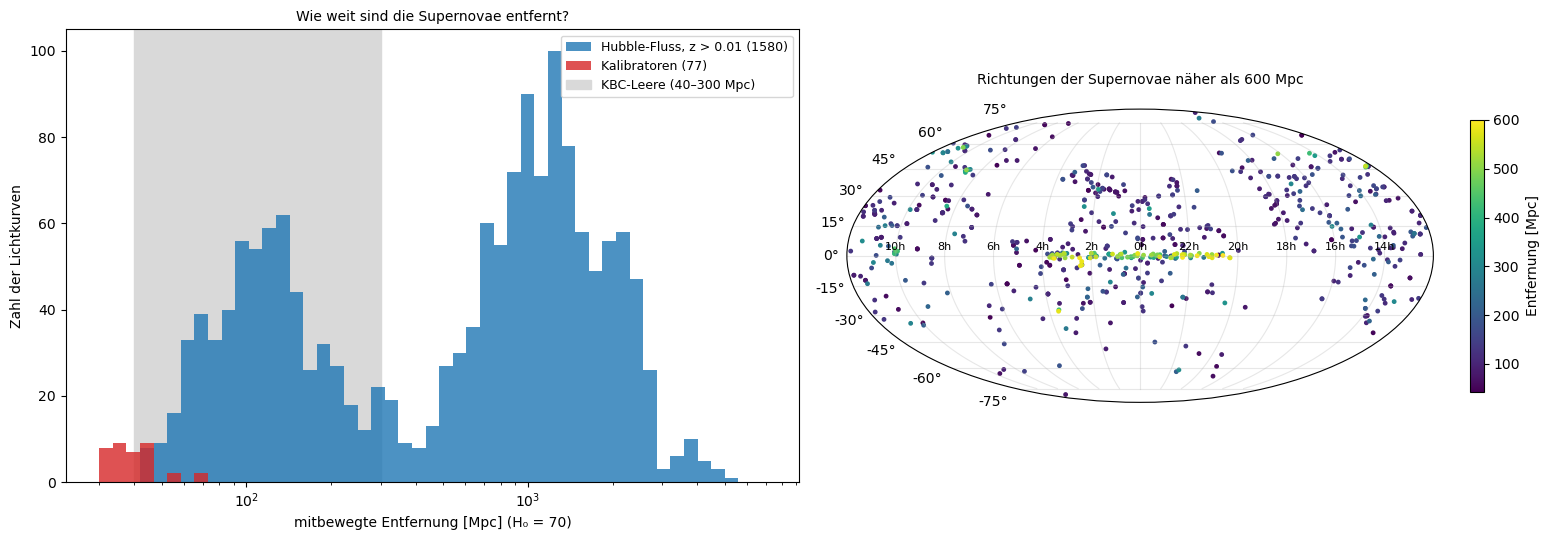

innerhalb (< 300 Mpc) :  585 Lichtkurven
Rand (300–600 Mpc)    :  109 Lichtkurven
außerhalb (> 600 Mpc) :  886 Lichtkurven
300 Mpc entsprechen z = 0.071; Kalibratoren bis 72 Mpc


In [3]:
r_all = C_KMS * comoving(SN["zHD"].values) / 70.0
use = (SN["zHD"].values > Z_MIN) & ~CAL
groups = {"innerhalb (< 300 Mpc)": use & (r_all < 300), "Rand (300–600 Mpc)": use & (r_all >= 300) & (r_all < 600),
          "außerhalb (> 600 Mpc)": use & (r_all >= 600)}
fig = plt.figure(figsize=(16, 5.5))
ax = fig.add_subplot(1, 2, 1)
bins = np.logspace(np.log10(30), np.log10(7000), 50)
ax.hist(r_all[use], bins=bins, color="C0", alpha=0.8, label=f"Hubble-Fluss, z > {Z_MIN} ({use.sum()})")
ax.hist(r_all[CAL], bins=bins, color="C3", alpha=0.8, label=f"Kalibratoren ({CAL.sum()})")
ax.axvspan(40, KBC["R"], color="0.85", zorder=0, label="KBC-Leere (40–300 Mpc)")
ax.set_xscale("log")
ax.set_xlabel("mitbewegte Entfernung [Mpc] (H₀ = 70)")
ax.set_ylabel("Zahl der Lichtkurven")
ax.set_title("Wie weit sind die Supernovae entfernt?", fontsize=10)
ax.legend(fontsize=9)
ax = fig.add_subplot(1, 2, 2, projection="mollweide")
ra = np.radians(SN["RA"].values)
ra = np.where(ra > np.pi, ra - 2 * np.pi, ra)
m = use & (r_all < 600)
sc = ax.scatter(-ra[m], np.radians(SN["DEC"].values[m]), c=r_all[m], s=6, cmap="viridis", vmax=600)
plt.colorbar(sc, ax=ax, shrink=0.6, label="Entfernung [Mpc]")
ax.set_xticklabels([f"{int(((-x) % 360) / 15)}h" for x in range(-150, 151, 30)], fontsize=8)
ax.grid(alpha=0.3)
ax.set_title("Richtungen der Supernovae näher als 600 Mpc", fontsize=10, pad=18)
plt.tight_layout()
plt.show()

for k, g in groups.items():
    print(f"{k:22s}: {g.sum():4d} Lichtkurven")
print(f"300 Mpc entsprechen z = {np.interp(300, r_all[np.argsort(r_all)], SN['zHD'].values[np.argsort(r_all)]):.3f}; "
      f"Kalibratoren bis {r_all[CAL].max():.0f} Mpc")

PLATZHALTER ERKL1

#### **Reduktion**

##### *2. Der Ausgangswert*

Wie groß ist H₀ ohne Leere, mit und ohne Korrektur der Eigenbewegungen? Vorher vorhersagen: Ändert die Wahl der Rotverschiebung H₀ um mehr oder weniger als den statistischen Fehler von 1 km/s/Mpc?

Wie im Hubble-Diagramm passt der Code M_B und H₀ gemeinsam an, hier mit allen Supernovae über z = 0.01 und den Kalibratoren, einmal mit zHD, einmal mit zCMB. Weil das Modell linear in M_B und 5 log₁₀ H₀ ist, gibt es eine geschlossene Lösung (verallgemeinerte kleinste Quadrate, Theorie, Abschnitt 3).

**Hintergrund & Fachbegriffe:**
- **H_out:** In einem Modell mit Leere ist das die Hubble-Rate außerhalb, die des ganzen Universums; ohne Leere ist sie einfach H₀.
- **Geschlossene Lösung:** β = (XᵀC⁻¹X)⁻¹XᵀC⁻¹y; jede Leere ändert nur y, die Matrizen bleiben gleich, deshalb kostet ein Fit für ein ganzes Gitter von Leeren nur Sekunden.

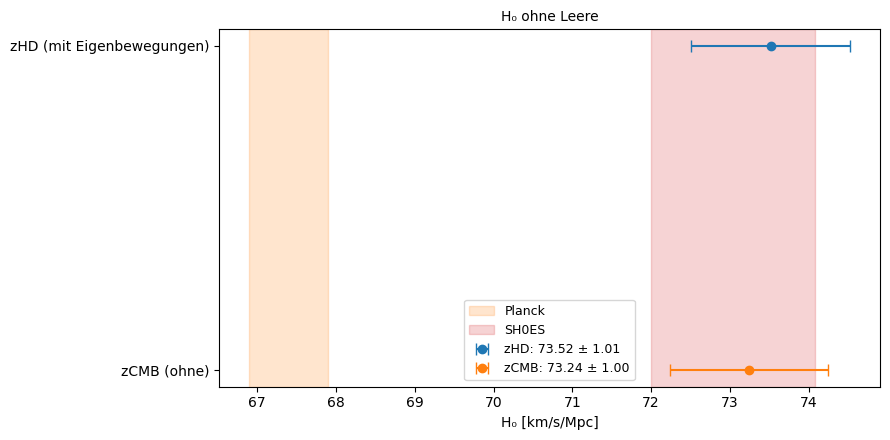

zHD: M_B = -19.2439, H₀ = 73.52, χ² = 1452.0 bei 1655 Freiheitsgraden
zCMB: M_B = -19.2444, H₀ = 73.24, χ² = 1489.7 bei 1653 Freiheitsgraden


In [4]:
FITS = {zc: VoidFit(zc) for zc in ("zHD", "zCMB")}
BASE_FIT = {zc: f.fit() for zc, f in FITS.items()}
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (zc, (chi2, M, H)) in enumerate(BASE_FIT.items()):
    F = FITS[zc]
    cov_b = F.Finv
    eH = H * np.log(10) / 5 * np.sqrt(cov_b[1, 1])
    ax.errorbar(H, -i, xerr=eH, fmt="o", capsize=4, color=f"C{i}", label=f"{zc}: {H:.2f} ± {eH:.2f}")
for (v, e), col, lab in [(H0_PLANCK, "C1", "Planck"), (H0_SH0ES, "C3", "SH0ES")]:
    ax.axvspan(v - e, v + e, color=col, alpha=0.2, label=lab)
ax.set_yticks([0, -1])
ax.set_yticklabels(["zHD (mit Eigenbewegungen)", "zCMB (ohne)"])
ax.set_xlabel("H₀ [km/s/Mpc]")
ax.set_title("H₀ ohne Leere", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
for zc, (chi2, M, H) in BASE_FIT.items():
    print(f"{zc}: M_B = {M:.4f}, H₀ = {H:.2f}, χ² = {chi2:.1f} bei {len(FITS[zc].idx) - 2} Freiheitsgraden")

PLATZHALTER ERKL2

##### *3. Was die Korrektur der Eigenbewegungen tut*

Rechnet die Korrektur zHD eine große Leere schon heraus? Vorher vorhersagen: Wenn wir in einer Leere von 300 Mpc mit δ = −0.46 säßen, welche Geschwindigkeit hätte eine Galaxie in 200 Mpc relativ zur reinen Expansion?

In einer Leere strömt Materie nach außen, mit v = −f δ̄ H r / 3 (Theorie, Abschnitt 2). Enthielte das Modell, aus dem zHD berechnet ist, eine solche Leere, wäre c(zHD − zCMB) im Mittel negativ und würde mit r anwachsen. Der Code zeigt den Median der Korrektur in Entfernungsintervallen und daneben, was die KBC-Leere verlangen würde.

**Hintergrund & Fachbegriffe:**
- **Ausströmen:** Materie in einer Unterdichte wird von der dichteren Umgebung nach außen gezogen; die Galaxien entfernen sich schneller als mit der Expansion allein.
- **2M++:** ein Katalog von Galaxien bis etwa 200 Mpc/h; aus ihrer Verteilung folgt in linearer Theorie das Geschwindigkeitsfeld, mit dem Pantheon+ die Eigenbewegungen korrigiert.

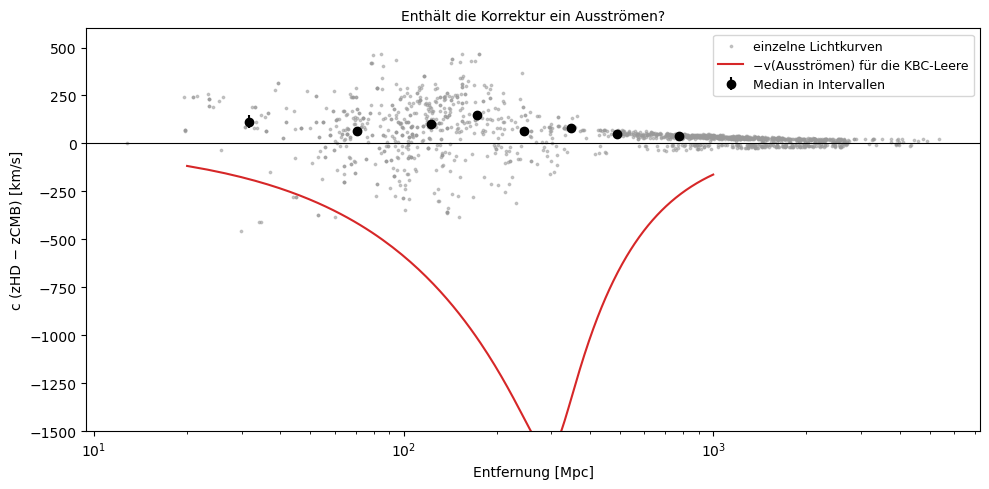

  20 bis   50 Mpc: Median c(zHD − zCMB) =   +114 km/s; KBC verlangt   -186
  50 bis  100 Mpc: Median c(zHD − zCMB) =    +66 km/s; KBC verlangt   -415
 100 bis  150 Mpc: Median c(zHD − zCMB) =   +102 km/s; KBC verlangt   -719
 150 bis  200 Mpc: Median c(zHD − zCMB) =   +147 km/s; KBC verlangt  -1017
 200 bis  300 Mpc: Median c(zHD − zCMB) =    +63 km/s; KBC verlangt  -1432
 300 bis  400 Mpc: Median c(zHD − zCMB) =    +78 km/s; KBC verlangt  -1341
 400 bis  600 Mpc: Median c(zHD − zCMB) =    +51 km/s; KBC verlangt   -677
 600 bis 1000 Mpc: Median c(zHD − zCMB) =    +39 km/s; KBC verlangt   -271


In [5]:
rz = C_KMS * comoving(SN["zCMB"].values) / 70.0
dv = C_KMS * (SN["zHD"].values - SN["zCMB"].values)
edges = np.array([20, 50, 100, 150, 200, 300, 400, 600, 1000])
mid, med, err = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    s = (rz >= lo) & (rz < hi) & ~CAL
    mid.append(np.sqrt(lo * hi))
    med.append(np.median(dv[s]))
    err.append(1.2533 * np.std(dv[s]) / np.sqrt(s.sum()))
rr = np.linspace(20, 1000, 300)
v_kbc = -F_GROWTH * mean_contrast(rr, KBC["delta"], KBC["R"]) / 3 * 70 * rr      # Ausströmen bei H = 70
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(rz[~CAL], dv[~CAL], s=3, color="0.6", alpha=0.5, label="einzelne Lichtkurven")
ax.errorbar(mid, med, yerr=err, fmt="ko", label="Median in Intervallen")
ax.plot(rr, -v_kbc, "C3-", label="−v(Ausströmen) für die KBC-Leere")
ax.axhline(0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_ylim(-1500, 600)
ax.set_xlabel("Entfernung [Mpc]")
ax.set_ylabel("c (zHD − zCMB) [km/s]")
ax.set_title("Enthält die Korrektur ein Ausströmen?", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
for a, b, v in zip(edges[:-1], edges[1:], med):
    print(f"{a:4d} bis {b:4d} Mpc: Median c(zHD − zCMB) = {v:+6.0f} km/s; KBC verlangt {-np.interp(np.sqrt(a * b), rr, v_kbc):+6.0f}")

PLATZHALTER ERKL3

#### **Eigene Messung**

##### *4. H₀ in Schalen*

Bleibt H₀ gleich, wenn man nur Supernovae einer bestimmten Entfernung nimmt, oder fällt es jenseits von 300 Mpc ab? Vorher vorhersagen: Welches H₀ würde man in der Schale von 0.1 < z < 0.15 messen, wenn die KBC-Leere die ganze Spannung erklärt?

Mit M_B aus dem gemeinsamen Fit (Schritt 2) gibt jede Supernova ein eigenes H₀: log₁₀ H₀ = 0.2 (M_B + 25 − m) + log₁₀(c (1 + z_hel) D(z)). Der Code mittelt das in Schalen der Rotverschiebung mit der vollen Kovarianz der Schale. Der gemeinsame Fehler von M_B (etwa ±1 km/s/Mpc) verschiebt alle Schalen gleich und ist deshalb getrennt eingezeichnet. Dazu die Erwartung einer KBC-Leere, die von außen 67.4 auf innen 73 anhebt.

**Hintergrund & Fachbegriffe:**
- **Schale:** alle Supernovae in einem Bereich von z; ihr gemeinsames H₀ misst die mittlere Expansion bis zu dieser Entfernung.
- **Gemeinsamer Fehler:** ein Fehler, der alle Punkte gleich verschiebt (hier M_B); er ändert die Höhe der Kurve, nicht ihre Form, und die Form ist es, die eine Leere verraten würde.

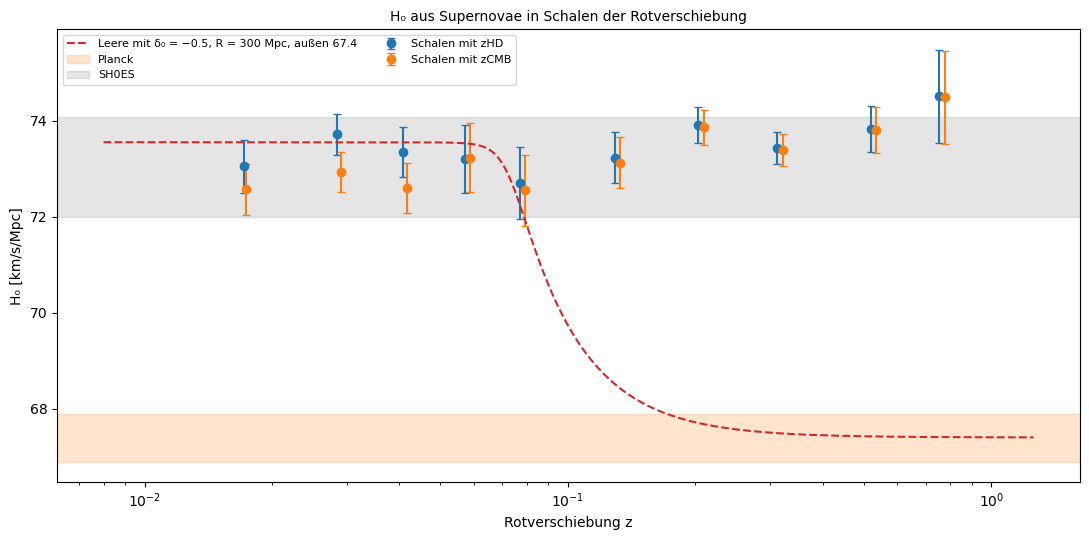

 z_lo  z_hi  z_med   n     H0   err        r
0.010 0.023  0.017 215 73.047 0.551   73.345
0.023 0.035  0.028 208 73.714 0.423  121.141
0.035 0.050  0.041 101 73.346 0.512  172.813
0.050 0.070  0.057  52 73.204 0.708  241.350
0.070 0.100  0.077  44 72.702 0.747  324.019
0.100 0.150  0.129  85 73.223 0.533  535.119
0.150 0.250  0.203 261 73.910 0.368  825.288
0.250 0.400  0.312 306 73.426 0.332 1230.128
0.400 0.700  0.519 233 73.824 0.476 1926.746
0.700 1.200  0.755  56 74.505 0.965 2619.937
zHD: H₀ für z < 0.07 73.40 ± 0.26, für 0.1 < z < 0.4 73.57 ± 0.22; Unterschied -0.17 ± 0.34


In [6]:
SHELLS = [0.01, 0.0233, 0.035, 0.05, 0.07, 0.1, 0.15, 0.25, 0.4, 0.7, 1.2]


def shell_h0(zcol, M):
    z, zh, m = SN[zcol].values, SN["zHEL"].values, SN["m_b_corr"].values
    y = 0.2 * (M + 25 - m) + np.log10(C_KMS * (1 + zh) * comoving(z))
    out = []
    for lo, hi in zip(SHELLS[:-1], SHELLS[1:]):
        idx = np.where((z > lo) & (z < hi) & ~CAL)[0]
        Ci = np.linalg.inv(0.04 * subcov(idx))
        one = np.ones(len(idx))
        yb, ey = (one @ Ci @ y[idx]) / (one @ Ci @ one), 1 / np.sqrt(one @ Ci @ one)
        out.append(dict(z_lo=lo, z_hi=hi, z_med=np.median(z[idx]), n=len(idx), H0=10**yb, err=10**yb * np.log(10) * ey,
                        r=C_KMS * comoving(np.median(z[idx])) / 70))
    return pd.DataFrame(out)


SH = {zc: shell_h0(zc, BASE_FIT[zc][1]) for zc in FITS}
zz = np.logspace(np.log10(0.008), 0.1, 300)
r_zz = C_KMS * comoving(zz) / 70
kbc_curve = H0_PLANCK[0] * h_ratio(r_zz, -0.5, KBC["R"])
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, (zc, df) in enumerate(SH.items()):
    ax.errorbar(df["z_med"] * (1 + 0.03 * i), df["H0"], yerr=df["err"], fmt="o", capsize=3, color=f"C{i}", label=f"Schalen mit {zc}")
ax.plot(zz, kbc_curve, "C3--", label="Leere mit δ₀ = −0.5, R = 300 Mpc, außen 67.4")
for (v, e), col, lab in [(H0_PLANCK, "C1", "Planck"), (H0_SH0ES, "0.5", "SH0ES")]:
    ax.axhspan(v - e, v + e, color=col, alpha=0.2, label=lab)
ax.set_xscale("log")
ax.set_xlabel("Rotverschiebung z")
ax.set_ylabel("H₀ [km/s/Mpc]")
ax.set_title("H₀ aus Supernovae in Schalen der Rotverschiebung", fontsize=10)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
print(SH["zHD"].round(3).to_string(index=False))
lo_z, hi_z = SH["zHD"].query("z_hi <= 0.07"), SH["zHD"].query("z_lo >= 0.1 and z_hi <= 0.4")
w = lambda df: (np.sum(df["H0"] / df["err"] ** 2) / np.sum(1 / df["err"] ** 2), 1 / np.sqrt(np.sum(1 / df["err"] ** 2)))
a, b = w(lo_z), w(hi_z)
print(f"zHD: H₀ für z < 0.07 {a[0]:.2f} ± {a[1]:.2f}, für 0.1 < z < 0.4 {b[0]:.2f} ± {b[1]:.2f}; Unterschied {a[0] - b[0]:+.2f} ± {np.hypot(a[1], b[1]):.2f}")

##### *5. Was eine Leere vorhersagt*

Wie würde H₀ mit der Entfernung verlaufen, wenn wir in einer Leere säßen, und wie tief müsste sie sein? Vorher vorhersagen: Wie tief muss eine Leere sein, damit H₀ innen 9 % größer ist als außen?

Der Code zeigt links das Profil δ(r) und den mittleren Kontrast δ̄(<r) einer Leere mit weichem Rand, rechts die scheinbare Hubble-Rate H_lokal(r)/H_out = 1 − f δ̄(<r)/3 für einige Tiefen und Radien. Jenseits des Randes fällt δ̄(<r) wie (R/r)³, weil die Leere in einer immer größeren Kugel immer weniger ausmacht.

**Hintergrund & Fachbegriffe:**
- **Mittlerer Kontrast in einer Kugel:** δ̄(<r) = (3/r³)∫δ(r') r'² dr'; nach dem Satz von Gauß bestimmt nur die Masse innerhalb von r, wie stark die Kugel abgebremst wird.
- **Wachstumsrate f:** wie schnell Dichteschwankungen wachsen, f = d ln δ / d ln a ≈ Ω_m^0.55 = 0.55 heute; sie verbindet Dichte und Geschwindigkeit.
- **Lineare Theorie:** gilt für |δ| ≪ 1; bei δ = −0.5 ist sie nur eine grobe Näherung, die Größenordnung stimmt aber.

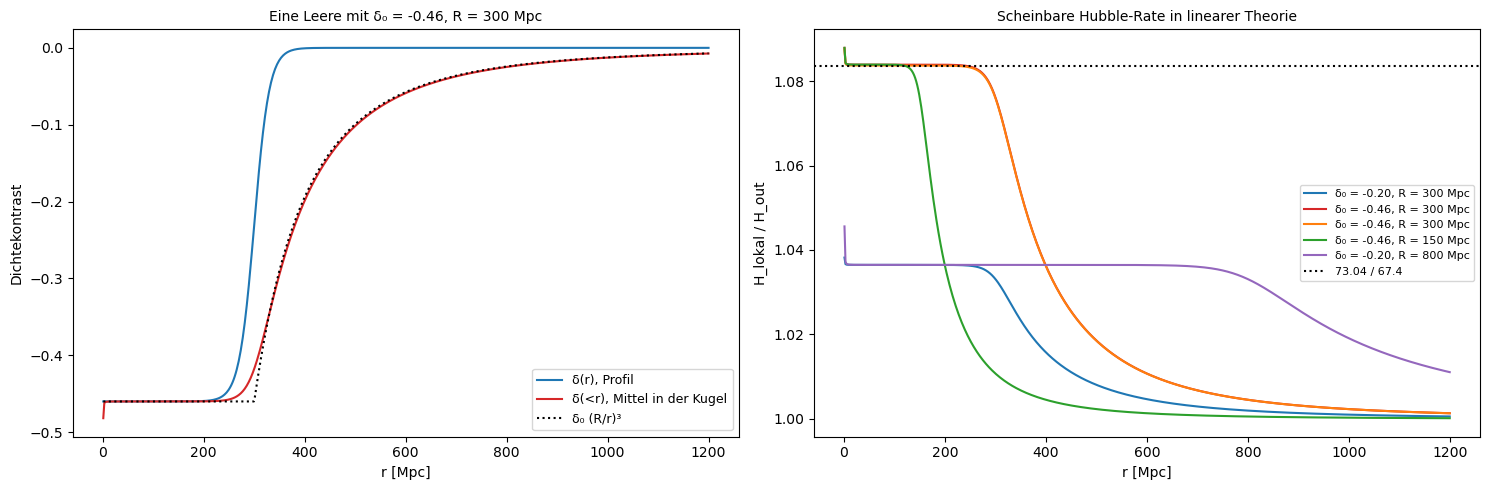

f = 0.547; für H_lokal/H_out = 1.084 braucht man δ̄ = -0.459
δ₀ = -0.46, R = 300: H_lokal/H_out bei 100 Mpc 1.0839, bei 600 Mpc 1.0107
δ₀ = -0.2, R = 300: H_lokal/H_out bei 100 Mpc 1.0365, bei 600 Mpc 1.0047


In [7]:
rr = np.linspace(1, 1200, 600)
DELTA_NEED = -3 * (H0_SH0ES[0] / H0_PLANCK[0] - 1) / F_GROWTH
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
prof = KBC["delta"] * 0.5 * (1 - np.tanh((rr - KBC["R"]) / (EDGE_WIDTH * KBC["R"])))
ax.plot(rr, prof, "C0-", label="δ(r), Profil")
ax.plot(rr, mean_contrast(rr, KBC["delta"], KBC["R"]), "C3-", label="δ̄(<r), Mittel in der Kugel")
ax.plot(rr, KBC["delta"] * np.minimum(1, (KBC["R"] / rr) ** 3), "k:", label="δ₀ (R/r)³")
ax.set_xlabel("r [Mpc]")
ax.set_ylabel("Dichtekontrast")
ax.set_title(f"Eine Leere mit δ₀ = {KBC['delta']}, R = {KBC['R']:.0f} Mpc", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
for (d0, R), col in [((-0.2, 300), "C0"), ((-0.46, 300), "C3"), ((DELTA_NEED, 300), "C1"), ((-0.46, 150), "C2"), ((-0.2, 800), "C4")]:
    ax.plot(rr, h_ratio(rr, d0, R), color=col, label=f"δ₀ = {d0:.2f}, R = {R} Mpc")
ax.axhline(H0_SH0ES[0] / H0_PLANCK[0], color="k", ls=":", label="73.04 / 67.4")
ax.set_xlabel("r [Mpc]")
ax.set_ylabel("H_lokal / H_out")
ax.set_title("Scheinbare Hubble-Rate in linearer Theorie", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"f = {F_GROWTH:.3f}; für H_lokal/H_out = {H0_SH0ES[0] / H0_PLANCK[0]:.3f} braucht man δ̄ = {DELTA_NEED:.3f}")
for d0, R in [(-0.46, 300), (-0.2, 300)]:
    print(f"δ₀ = {d0}, R = {R}: H_lokal/H_out bei 100 Mpc {h_ratio(np.array([100.]), d0, R)[0]:.4f}, bei 600 Mpc {h_ratio(np.array([600.]), d0, R)[0]:.4f}")

PLATZHALTER ERKL5

#### **Modell und Fit**

##### *6. Fit des Void-Modells*

Welche Tiefe und welchen Radius einer Leere lassen die Supernovae zu? Vorher vorhersagen: Wird die erlaubte Tiefe bei großem R enger oder weiter, und warum?

Für jedes Paar (δ₀, R) auf einem Gitter passt der Code M_B und H_out an und speichert χ²; das Minimum über M_B und H_out ist in geschlossener Form (Schritt 2). Links die Karte Δχ² gegen das Modell ohne Leere (mit zHD), mit dem Punkt der KBC-Leere; rechts der erlaubte Bereich von δ₀ für jeden Radius (Δχ² < 4 bei festem R), für zHD und zCMB.

**Hintergrund & Fachbegriffe:**
- **Profil bei festem R:** Für jeden Radius ist δ₀ ein einzelner Parameter; Δχ² < 4 entspricht 2σ.
- **Verschachtelte Modelle:** Das Modell ohne Leere ist der Spezialfall δ₀ = 0; Δχ² gegen dieses Modell misst, ob die Leere die Daten besser beschreibt.

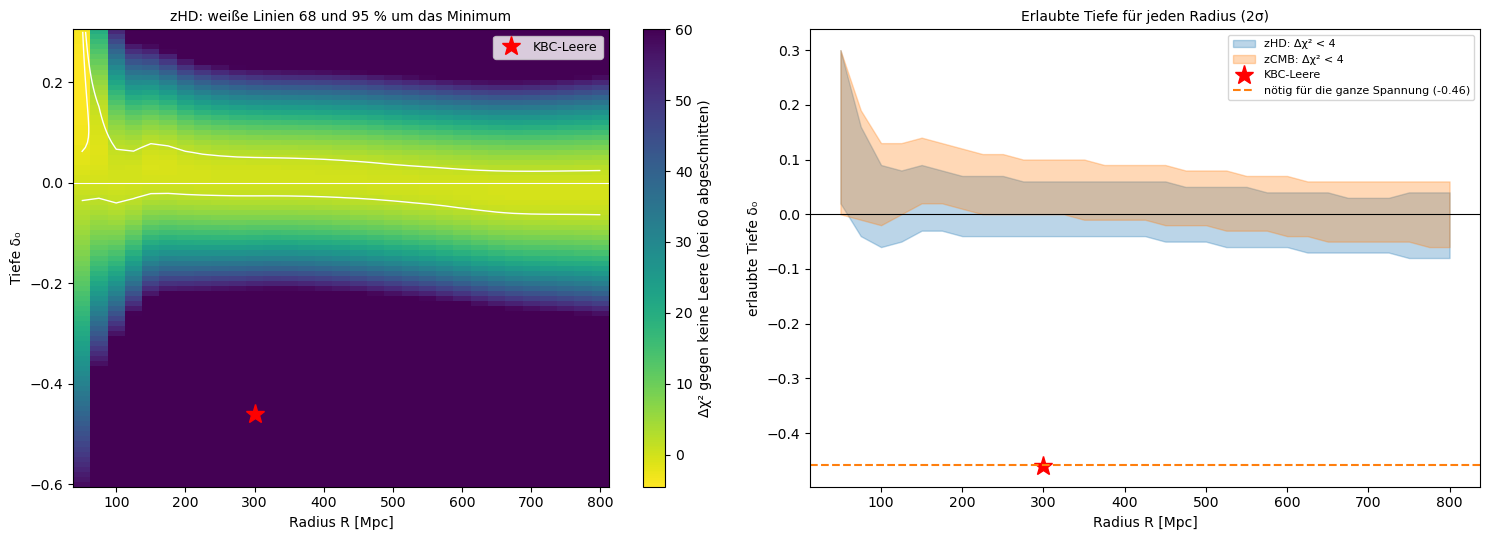

zHD: Minimum bei δ₀ = +0.21, R = 50 Mpc (Δχ² = -4.5); bei R = 300 Mpc erlaubt -0.040 bis +0.060; KBC-Leere Δχ² = 253
zCMB: Minimum bei δ₀ = +0.08, R = 150 Mpc (Δχ² = -5.8); bei R = 300 Mpc erlaubt -0.000 bis +0.100; KBC-Leere Δχ² = 293


In [8]:
GRID = {}
for zc, F in FITS.items():
    GRID[zc] = np.array([[F.fit(d0, R)[0] for R in R_GRID] for d0 in D_GRID]) - BASE_FIT[zc][0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
im = ax.pcolormesh(R_GRID, D_GRID, np.clip(GRID["zHD"], -5, 60), cmap="viridis_r", shading="auto")
plt.colorbar(im, ax=ax, label="Δχ² gegen keine Leere (bei 60 abgeschnitten)")
ax.contour(R_GRID, D_GRID, GRID["zHD"] - GRID["zHD"].min(), levels=[2.30, 6.18], colors="w", linewidths=1)
ax.plot(KBC["R"], KBC["delta"], "r*", ms=14, label="KBC-Leere")
ax.axhline(0, color="w", lw=0.8)
ax.set_xlabel("Radius R [Mpc]")
ax.set_ylabel("Tiefe δ₀")
ax.set_title("zHD: weiße Linien 68 und 95 % um das Minimum", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
LIMITS = {}
for i, (zc, G) in enumerate(GRID.items()):
    lo, hi = [], []
    for j in range(len(R_GRID)):
        col = G[:, j] - G[:, j].min()
        ok = D_GRID[col < 4]
        lo.append(ok.min())
        hi.append(ok.max())
    LIMITS[zc] = (np.array(lo), np.array(hi))
    ax.fill_between(R_GRID, lo, hi, color=f"C{i}", alpha=0.3, label=f"{zc}: Δχ² < 4")
ax.plot(KBC["R"], KBC["delta"], "r*", ms=14, label="KBC-Leere")
ax.axhline(DELTA_NEED, color="C1", ls="--", label=f"nötig für die ganze Spannung ({DELTA_NEED:.2f})")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Radius R [Mpc]")
ax.set_ylabel("erlaubte Tiefe δ₀")
ax.set_title("Erlaubte Tiefe für jeden Radius (2σ)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for zc, G in GRID.items():
    i, j = np.unravel_index(np.argmin(G), G.shape)
    kbc = FITS[zc].fit(KBC["delta"], KBC["R"])[0] - BASE_FIT[zc][0]
    jr = np.argmin(np.abs(R_GRID - 300))
    print(f"{zc}: Minimum bei δ₀ = {D_GRID[i]:+.2f}, R = {R_GRID[j]:.0f} Mpc (Δχ² = {G[i, j]:+.1f}); "
          f"bei R = 300 Mpc erlaubt {LIMITS[zc][0][jr]:+.3f} bis {LIMITS[zc][1][jr]:+.3f}; KBC-Leere Δχ² = {kbc:.0f}")

PLATZHALTER ERKL6

##### *7. Kann eine Leere die Spannung erklären?*

Wenn das Universum außerhalb tatsächlich mit Plancks 67.4 km/s/Mpc expandiert, gibt es dann irgendeine Leere, mit der die Supernovae zusammenpassen? Vorher vorhersagen: Hilft eine sehr große Leere (R von 1 Gpc), weil dann auch die fernen Supernovae noch innen liegen?

Der Code hält H_out = 67.4 fest und sucht auf einem erweiterten Gitter (R bis 2000 Mpc) die beste Leere. Verglichen wird χ² mit dem besten Modell ohne Leere und freiem H₀. Links Δχ² der erzwungenen Leere gegen R (für jedes R mit der besten Tiefe), rechts die H₀-Schalen aus Schritt 4 mit der besten erzwungenen Leere.

**Hintergrund & Fachbegriffe:**
- **Erzwungenes Modell:** ein Modell, dessen Parameter teils von außen festgelegt sind (hier H_out von Planck); Δχ² gegen das freie Modell misst, wie viel schlechter die Daten damit beschrieben werden.
- **Fernes Ende:** Eine Leere hebt H nur bis zu ihrem Rand an; Supernovae bei z = 0.3 bis 1 messen die äußere Expansion. Eine Leere, die auch sie umfasst, müsste Gpc groß sein.

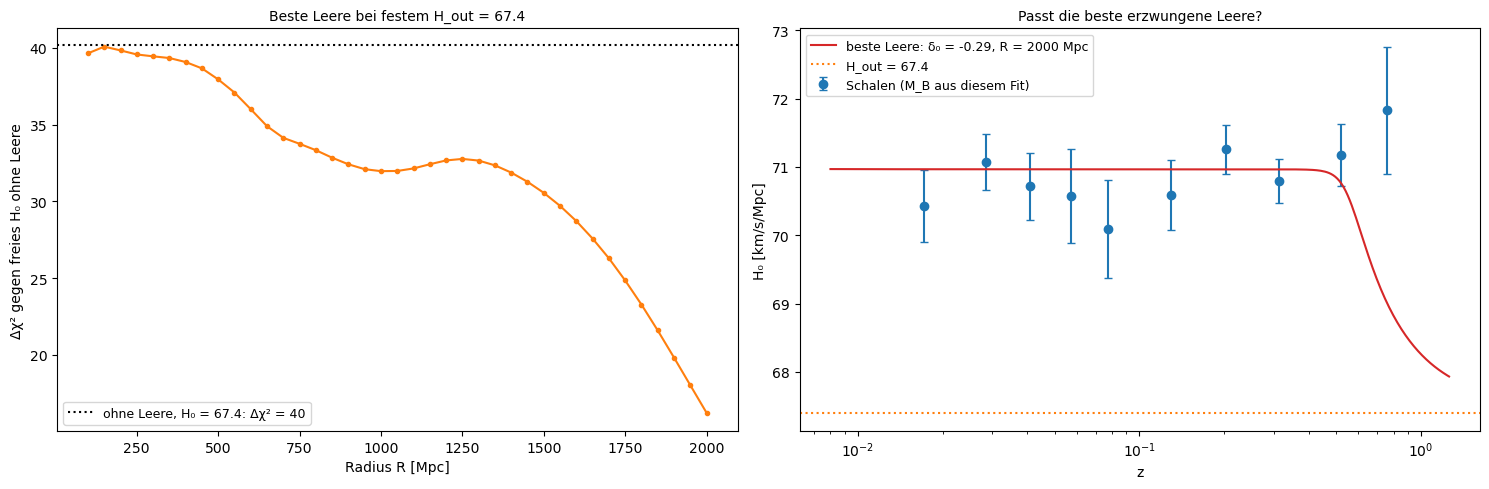

Beste Leere bei H_out = 67.4: δ₀ = -0.29, R = 2000 Mpc, Δχ² = 16.2 gegen freies H₀ ohne Leere (ohne Leere mit 67.4: 40.2); M_B dort -19.323
Δχ² bei R = 300, 600, 1000, 2000 Mpc: 39.4, 36.0, 32.0, 16.2


In [9]:
R_BIG = np.linspace(100, 2000, 39)
D_BIG = np.linspace(-0.7, 0.1, 81)
F = FITS["zHD"]
best_free = BASE_FIT["zHD"][0]
forced = np.array([[F.fit(d0, R, h_out=H0_PLANCK[0])[0] for R in R_BIG] for d0 in D_BIG]) - best_free
prof_R = forced.min(axis=0)
i, j = np.unravel_index(np.argmin(forced), forced.shape)
D_F, R_F = D_BIG[i], R_BIG[j]
no_void_forced = F.fit(0.0, 300.0, h_out=H0_PLANCK[0])[0] - best_free
_, M_F, _ = F.fit(D_F, R_F, h_out=H0_PLANCK[0])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(R_BIG, prof_R, "C1o-", ms=3)
ax.axhline(no_void_forced, color="k", ls=":", label=f"ohne Leere, H₀ = 67.4: Δχ² = {no_void_forced:.0f}")
ax.set_xlabel("Radius R [Mpc]")
ax.set_ylabel("Δχ² gegen freies H₀ ohne Leere")
ax.set_title("Beste Leere bei festem H_out = 67.4", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
df = shell_h0("zHD", M_F)
ax.errorbar(df["z_med"], df["H0"], yerr=df["err"], fmt="o", capsize=3, label="Schalen (M_B aus diesem Fit)")
zz = np.logspace(np.log10(0.008), 0.1, 300)
ax.plot(zz, H0_PLANCK[0] * h_ratio(C_KMS * comoving(zz) / 70, D_F, R_F), "C3-", label=f"beste Leere: δ₀ = {D_F:.2f}, R = {R_F:.0f} Mpc")
ax.axhline(H0_PLANCK[0], color="C1", ls=":", label="H_out = 67.4")
ax.set_xscale("log")
ax.set_xlabel("z")
ax.set_ylabel("H₀ [km/s/Mpc]")
ax.set_title("Passt die beste erzwungene Leere?", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f"Beste Leere bei H_out = 67.4: δ₀ = {D_F:.2f}, R = {R_F:.0f} Mpc, Δχ² = {forced.min():.1f} gegen freies H₀ ohne Leere "
      f"(ohne Leere mit 67.4: {no_void_forced:.1f}); M_B dort {M_F:.3f}")
print(f"Δχ² bei R = 300, 600, 1000, 2000 Mpc: " + ", ".join(f"{prof_R[np.argmin(np.abs(R_BIG - R))]:.1f}" for R in (300, 600, 1000, 2000)))

PLATZHALTER ERKL7

##### *8. Wie wahrscheinlich ist eine solche Leere in ΛCDM?*

Wie tief sind Leeren von 300 Mpc im Standardmodell typischerweise, und wie selten wäre die KBC-Leere? Vorher vorhersagen: Ist die typische Schwankung des Dichtekontrasts in einer Kugel von 300 Mpc eher 0.5, 0.1 oder 0.02?

Aus dem Leistungsspektrum (Eisenstein & Hu 1998 mit Planck-Parametern, normiert auf σ₈ = 0.811) folgt die Streuung σ(R) des mittleren Dichtekontrasts in Kugeln vom Radius R (Theorie, Abschnitt 4). Der Code vergleicht sie links mit der Tiefe, die für die ganze Spannung nötig wäre, und mit der KBC-Leere; rechts die Wahrscheinlichkeit, in Gaußscher Statistik eine so tiefe Leere zu finden, mit und ohne den Messfehler der KBC-Leere.

**Hintergrund & Fachbegriffe:**
- **σ(R):** die Standardabweichung des Dichtekontrasts gemittelt über Kugeln vom Radius R; σ(8 Mpc/h) = σ₈ ist die übliche Normierung.
- **Leistungsspektrum P(k):** die Varianz der Dichteschwankungen pro Wellenzahl; σ²(R) = (1/2π²)∫ k² P(k) W²(kR) dk mit der Fensterfunktion W einer Kugel.
- **Kosmische Varianz:** Selbst ohne besondere Leere misst ein Beobachter in einer endlichen Kugel ein H₀, das um f σ(R)/3 schwankt.

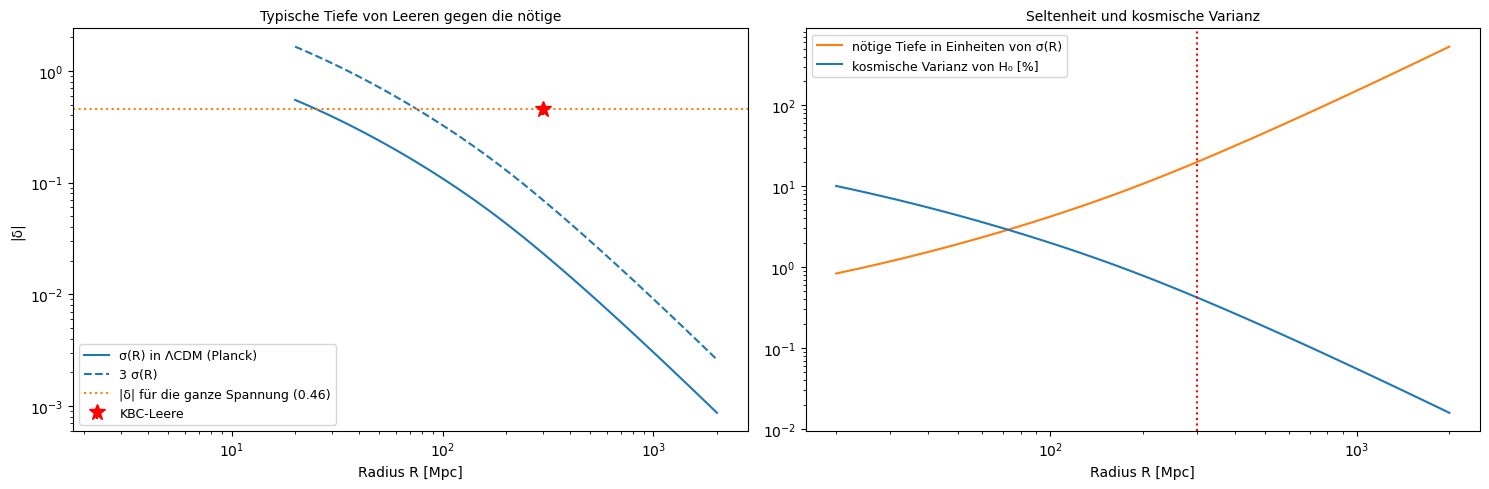

σ(300 Mpc) = 0.0232; nötig δ̄ = -0.459: 20 σ; KBC δ = -0.46: 20 σ, mit Messfehler ±0.06: 7.2 σ (p = 4e-13)
Kosmische Varianz von H₀ in 300 Mpc: 0.42 %, in 150 Mpc: 1.18 %


In [10]:
R_S = np.logspace(np.log10(20), np.log10(2000), 80)
SIG = np.array([sigma_R(R) for R in R_S])
sig_kbc = sigma_R(KBC["R"])
n_need = abs(DELTA_NEED) / sig_kbc
n_kbc = abs(KBC["delta"]) / sig_kbc
n_kbc_meas = abs(KBC["delta"]) / np.hypot(sig_kbc, KBC["err"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.loglog(R_S, SIG, "C0-", label="σ(R) in ΛCDM (Planck)")
ax.loglog(R_S, 3 * SIG, "C0--", label="3 σ(R)")
ax.axhline(abs(DELTA_NEED), color="C1", ls=":", label=f"|δ| für die ganze Spannung ({abs(DELTA_NEED):.2f})")
ax.errorbar(KBC["R"], abs(KBC["delta"]), yerr=KBC["err"], fmt="r*", ms=12, label="KBC-Leere")
ax.set_xlabel("Radius R [Mpc]")
ax.set_ylabel("|δ|")
ax.set_title("Typische Tiefe von Leeren gegen die nötige", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
ax.semilogy(R_S, abs(DELTA_NEED) / SIG, "C1-", label="nötige Tiefe in Einheiten von σ(R)")
ax.semilogy(R_S, 100 * F_GROWTH * SIG / 3, "C0-", label="kosmische Varianz von H₀ [%]")
ax.axvline(KBC["R"], color="r", ls=":")
ax.set_xscale("log")
ax.set_xlabel("Radius R [Mpc]")
ax.set_title("Seltenheit und kosmische Varianz", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f"σ(300 Mpc) = {sig_kbc:.4f}; nötig δ̄ = {DELTA_NEED:.3f}: {n_need:.0f} σ; KBC δ = {KBC['delta']}: {n_kbc:.0f} σ, "
      f"mit Messfehler ±{KBC['err']}: {n_kbc_meas:.1f} σ (p = {stats.norm.cdf(-n_kbc_meas):.0e})")
print(f"Kosmische Varianz von H₀ in 300 Mpc: {100 * F_GROWTH * sig_kbc / 3:.2f} %, in 150 Mpc: {100 * F_GROWTH * sigma_R(150) / 3:.2f} %")

PLATZHALTER ERKL8

##### *9. Bayes-Abwägung*

Wie stark sprechen die Supernovae gegen eine Leere, wenn man alle Tiefen und Radien gleichzeitig zulässt? Vorher vorhersagen: Kann ein Modell mit zwei zusätzlichen Parametern bei der Evidenz schlechter abschneiden als eines ohne, obwohl sein bestes χ² nie schlechter sein kann?

Die Evidenz eines Modells ist die Likelihood, gemittelt über die Prior-Verteilung seiner Parameter. M_B und H_out gehen in beiden Modellen linear ein und kürzen sich im Verhältnis heraus; übrig bleibt der Mittelwert von exp(−Δχ²/2) über die Prior-Verteilung von δ₀ und R (Theorie, Abschnitt 5). Zwei Priors: gleichverteilt (δ₀ von −0.6 bis 0.3, R von 50 bis 800 Mpc) und der von ΛCDM (δ₀ normalverteilt mit Breite σ(R), R gleichverteilt). Rechts die Posterior-Verteilung von δ₀ unter dem gleichverteilten Prior.

**Hintergrund & Fachbegriffe:**
- **Evidenz:** Z = ∫ L(θ) π(θ) dθ, die Wahrscheinlichkeit der Daten unter einem Modell, gemittelt über alles, was das Modell vorab erlaubt.
- **Bayes-Faktor:** B = Z₁/Z₀; ln B < −2.3 (B < 1/10) gilt nach der Skala von Jeffreys als starker Beleg gegen Modell 1.
- **Occam-Faktor:** Ein Modell, das viele Möglichkeiten zulässt, die die Daten nicht nutzen, verliert Evidenz; zusätzliche Parameter werden bestraft, wenn sie nicht gebraucht werden.

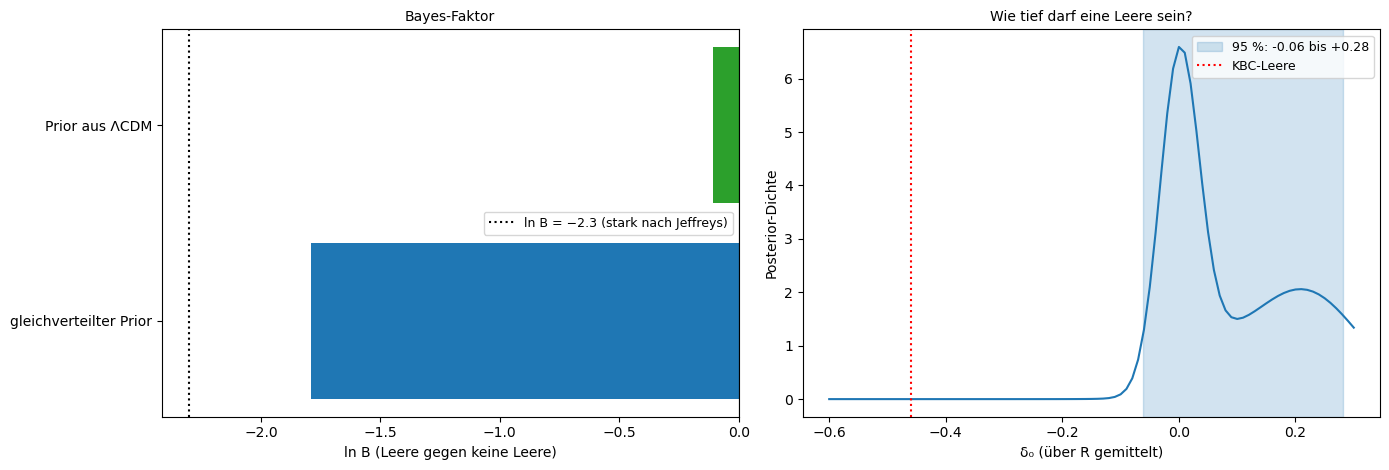

ln B (gleichverteilt) = -1.79, B = 0.167; ln B (ΛCDM-Prior) = -0.109
δ₀ Posterior: Median +0.035, 95 % -0.062 bis +0.282; bestes Δχ² auf dem Gitter -4.5


In [11]:
G = GRID["zHD"]
L = np.exp(-0.5 * (G - 0))                                           # Likelihood relativ zu "keine Leere"
dD, dR = D_GRID[1] - D_GRID[0], R_GRID[1] - R_GRID[0]
prior_flat = np.ones_like(G)
prior_flat /= prior_flat.sum()
SIG_GRID = np.array([sigma_R(R) for R in R_GRID])
prior_lcdm = stats.norm.pdf(D_GRID[:, None], 0, SIG_GRID[None, :])
prior_lcdm /= prior_lcdm.sum()
B_flat = np.sum(L * prior_flat)
B_lcdm = np.sum(L * prior_lcdm)
post = (L * prior_flat).sum(axis=1)
post /= post.sum() * dD
cdf = np.cumsum(post) * dD
d_lo, d_med, d_hi = np.interp([0.025, 0.5, 0.975], cdf, D_GRID)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
labels = ["gleichverteilter Prior", "Prior aus ΛCDM"]
vals = [np.log(B_flat), np.log(B_lcdm)]
ax.barh(labels, vals, color=["C0", "C2"])
ax.axvline(-2.3, color="k", ls=":", label="ln B = −2.3 (stark nach Jeffreys)")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("ln B (Leere gegen keine Leere)")
ax.set_title("Bayes-Faktor", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
ax.plot(D_GRID, post, "C0-")
ax.axvspan(d_lo, d_hi, color="C0", alpha=0.2, label=f"95 %: {d_lo:+.2f} bis {d_hi:+.2f}")
ax.axvline(KBC["delta"], color="r", ls=":", label="KBC-Leere")
ax.set_xlabel("δ₀ (über R gemittelt)")
ax.set_ylabel("Posterior-Dichte")
ax.set_title("Wie tief darf eine Leere sein?", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f"ln B (gleichverteilt) = {np.log(B_flat):.2f}, B = {B_flat:.3f}; ln B (ΛCDM-Prior) = {np.log(B_lcdm):.3f}")
print(f"δ₀ Posterior: Median {d_med:+.3f}, 95 % {d_lo:+.3f} bis {d_hi:+.3f}; bestes Δχ² auf dem Gitter {G.min():+.1f}")

PLATZHALTER ERKL9

#### **Eigene Messung gegen den Katalog**

##### *10. Gegen Kenworthy et al. und Haslbauer et al.*

Wie passen die eigenen Grenzen zu den veröffentlichten, und warum kommen Haslbauer et al. trotzdem zu dem Schluss, die Leere könne die Spannung erklären? Vorher vorhersagen: Welches Ergebnis ändert sich, wenn man statt ΛCDM eine Gravitation zulässt, in der Strukturen schneller wachsen?

Kenworthy, Scolnic & Riess (2019) haben mit 1295 Supernovae (Pantheon, Foundation, CSP) und einem Modell nach Lemaître-Tolman-Bondi gefunden, dass Unterdichten mit |δ| > 20 % mit 4 bis 5σ ausgeschlossen sind und die KBC-Leere mit 6.2σ. Haslbauer, Banik & Kroupa (2020) finden die KBC-Leere in einer großen ΛCDM-Simulation (MXXL) mit 6.04σ unwahrscheinlich und schlagen eine modifizierte Gravitation vor, in der solche Leeren entstehen und die schnellere lokale Expansion erzeugen. Der Code stellt die eigenen Zahlen daneben.

**Hintergrund & Fachbegriffe:**
- **Lemaître-Tolman-Bondi:** eine exakte Lösung der Allgemeinen Relativitätstheorie für ein kugelsymmetrisches, inhomogenes Universum; genauer als die lineare Theorie bei tiefen Leeren.
- **MOND:** Milgromsche Dynamik, eine Änderung der Gravitation bei sehr kleinen Beschleunigungen; in ihr wachsen Strukturen schneller, und tiefe Leeren wären häufiger.

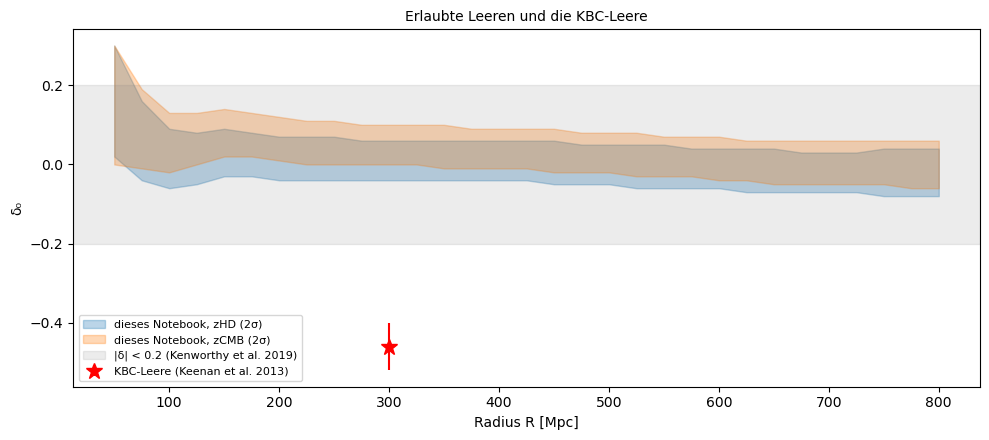

                                      Größe              dieses Notebook                                    Literatur
   Supernovae: KBC-Leere ausgeschlossen mit      16 σ (zHD), 17 σ (zCMB)                6.2 σ (Kenworthy et al. 2019)
Supernovae: erlaubte Tiefe bei 300 Mpc (2σ)              -0.04 bis +0.06 |δ| < 0.20 mit 4–5 σ (Kenworthy et al. 2019)
       ΛCDM: KBC-Leere unwahrscheinlich mit 7.2 σ (Gauß, mit Messfehler)         6.04 σ (Haslbauer et al. 2020, MXXL)
   Leere mit H_out = 67.4 gegen keine Leere                     Δχ² = 16                                            –


In [12]:
jr = np.argmin(np.abs(R_GRID - 300))
kbc_dchi = {zc: FITS[zc].fit(KBC["delta"], KBC["R"])[0] - BASE_FIT[zc][0] for zc in FITS}
rows = [("Supernovae: KBC-Leere ausgeschlossen mit", f"{np.sqrt(kbc_dchi['zHD']):.0f} σ (zHD), {np.sqrt(kbc_dchi['zCMB']):.0f} σ (zCMB)",
         "6.2 σ (Kenworthy et al. 2019)"),
        ("Supernovae: erlaubte Tiefe bei 300 Mpc (2σ)", f"{LIMITS['zHD'][0][jr]:+.2f} bis {LIMITS['zHD'][1][jr]:+.2f}",
         "|δ| < 0.20 mit 4–5 σ (Kenworthy et al. 2019)"),
        ("ΛCDM: KBC-Leere unwahrscheinlich mit", f"{n_kbc_meas:.1f} σ (Gauß, mit Messfehler)", "6.04 σ (Haslbauer et al. 2020, MXXL)"),
        ("Leere mit H_out = 67.4 gegen keine Leere", f"Δχ² = {forced.min():.0f}", "–")]
TAB = pd.DataFrame(rows, columns=["Größe", "dieses Notebook", "Literatur"])
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (zc, col) in enumerate([("zHD", "C0"), ("zCMB", "C1")]):
    lo, hi = LIMITS[zc]
    ax.fill_between(R_GRID, lo, hi, color=col, alpha=0.3, label=f"dieses Notebook, {zc} (2σ)")
ax.axhspan(-0.2, 0.2, color="0.5", alpha=0.15, label="|δ| < 0.2 (Kenworthy et al. 2019)")
ax.errorbar(KBC["R"], KBC["delta"], yerr=KBC["err"], fmt="r*", ms=12, label="KBC-Leere (Keenan et al. 2013)")
ax.set_xlabel("Radius R [Mpc]")
ax.set_ylabel("δ₀")
ax.set_title("Erlaubte Leeren und die KBC-Leere", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(TAB.to_string(index=False))

#### **Ergebnis**

PLATZHALTER

#### **Variationen**

PLATZHALTER

#### **Wiederholung**

PLATZHALTER

#### **Nächste Schritte**

PLATZHALTER

#### **Referenzen**

PLATZHALTER